# COU 07506 – Week 2 – Lab 1A: Sampling, Aliasing and Quantization
**Name:** Iddy Omary
**Registration number:** 240242439347
**Date:** 26 November 2026
**Group:** BEng24COE-2
**Git repository:** https://github.com/iddyiom/COU07506-labs

## Pre-lab
**(a)** F = 7 kHz, fs = 10 kHz: F > fs/2 = 5 kHz, so it aliases to |F − k·fs| = |7 − 10| = **3 kHz**.

**(b)** Δ = 2·Xm / 2^B = 2(1) / 2⁸ = 2/256 = **0.0078125 V** (≈ 7.81 mV).
SQNR ≈ 6.02·B + 1.76 = 6.02(8) + 1.76 = **49.9 dB**.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile
from IPython.display import Audio
plt.rcParams["figure.figsize"] = (9, 3.5)

## Task 2.1 – Aliasing of a sinusoid

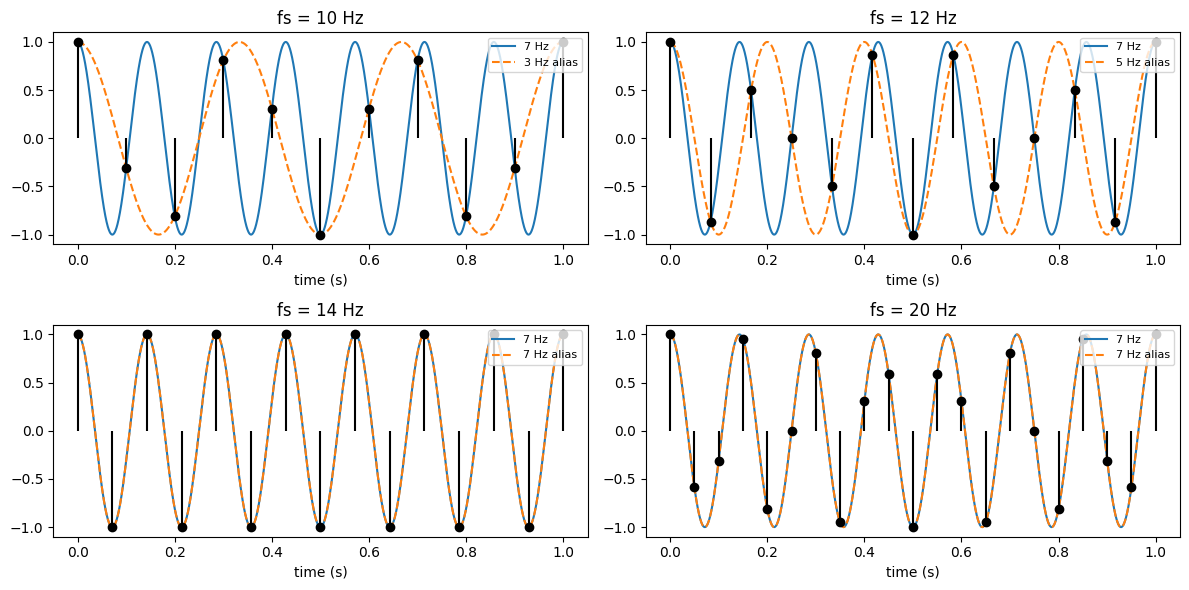

 fs (Hz) | fs/2 | alias |F-k*fs| | alias seen in DFT
     10  |    5 |    3.0        |    3.0
     12  |    6 |    5.0        |    5.0
     14  |    7 |    7.0        |    7.0
     20  |   10 |    7.0        |    7.0


In [2]:
f0 = 7.0
rows = []
fig, axes = plt.subplots(2, 2, figsize=(12, 6))
for ax, fs in zip(axes.ravel(), [10.0, 12.0, 14.0, 20.0]):
    t  = np.linspace(0, 1, 2000)             # dense grid = "analog" signal
    n  = np.arange(0, int(fs) + 1)
    tn = n / fs
    f_alias = abs(f0 - fs*round(f0/fs))
    ax.plot(t, np.cos(2*np.pi*f0*t), label=f"{f0:g} Hz")
    ax.plot(t, np.cos(2*np.pi*f_alias*t), "--", label=f"{f_alias:g} Hz alias")
    ax.stem(tn, np.cos(2*np.pi*f0*tn), linefmt="k-", markerfmt="ko", basefmt=" ")
    ax.set_title(f"fs = {fs:g} Hz"); ax.set_xlabel("time (s)"); ax.legend(loc="upper right", fontsize=8)
    # independent check: peak of the DFT of the sampled signal (longer record)
    ns = np.arange(int(fs*50)); xs = np.cos(2*np.pi*f0*ns/fs)
    f_meas = np.fft.rfftfreq(len(xs), 1/fs)[np.argmax(np.abs(np.fft.rfft(xs)))]
    rows.append((fs, fs/2, f_alias, f_meas))
plt.tight_layout(); plt.show()

print(" fs (Hz) | fs/2 | alias |F-k*fs| | alias seen in DFT")
for fs, fn, fa, fm in rows:
    print(f"  {fs:5.0f}  | {fn:4.0f} |   {fa:4.1f}        |   {fm:4.1f}")

**Alias table (F = 7 Hz):**

| fs (Hz) | fs/2 (Hz) | Aliased? | Alias = \|F − k·fs\| (Hz) |
|---|---|---|---|
| 10 | 5 | yes | \|7 − 10\| = 3 |
| 12 | 6 | yes | \|7 − 12\| = 5 |
| 14 | 7 | borderline (F = fs/2) | \|7 − 14\| = 7 – no frequency shift, but the samples sit on the peaks/zero-crossings so amplitude depends on phase |
| 20 | 10 | no | 7 (correct) |

The measured (DFT) alias agrees with the formula in every case.

## Task 2.2 – Hear aliasing

In [3]:
import os
fname = "my_voice.wav"                     # your Week 1 recording
if os.path.exists(fname):
    fs, x = wavfile.read(fname)
    x = x.mean(axis=1) if x.ndim > 1 else x.astype(float)
    x = x / np.max(np.abs(x))
else:                                      # fallback: a 44.1 kHz chirp 200 Hz -> 15 kHz
    fs = 44100
    t = np.arange(0, 3, 1/fs)
    x = 0.5*signal.chirp(t, 200, 3, 15000)
print("original fs =", fs, "Hz,", len(x), "samples")
Audio(x, rate=fs)

original fs = 16000 Hz, 80896 samples


2 new fs = 8000 Hz   (Nyquist = 4000 Hz)
4 new fs = 4000 Hz   (Nyquist = 2000 Hz)
8 new fs = 2000 Hz   (Nyquist = 1000 Hz)


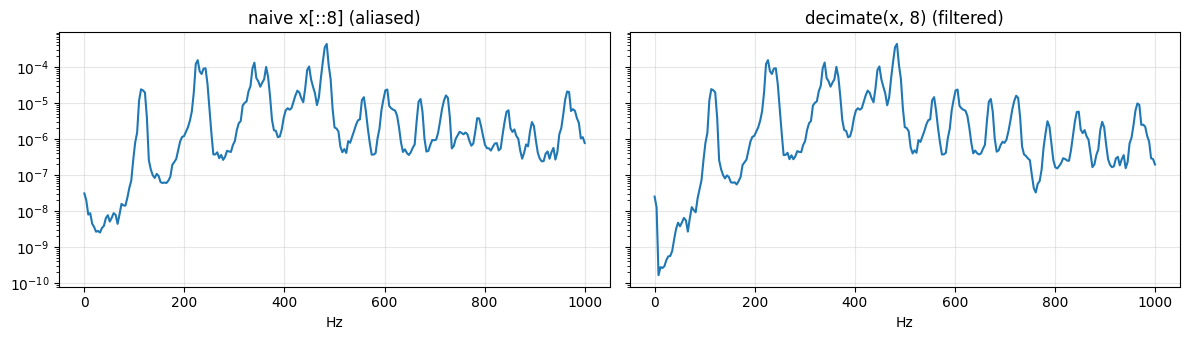

In [4]:
versions = {}
for k in [2, 4, 8]:
    naive  = x[::k]                              # no filter -> aliasing
    proper = signal.decimate(x, k, ftype="fir")  # low-pass, then drop
    versions[k] = (naive, proper)
    print(k, "new fs =", fs // k, "Hz   (Nyquist =", fs // k // 2, "Hz)")

# spectra for k = 8
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5), sharey=True)
for ax, sig_, name in zip(axes, versions[8], ["naive x[::8] (aliased)", "decimate(x, 8) (filtered)"]):
    f, P = signal.welch(sig_, fs=fs//8, nperseg=512)
    ax.semilogy(f, P); ax.set_title(name); ax.set_xlabel("Hz"); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

In [5]:
Audio(versions[8][0], rate=fs//8)   # k = 8, naive (no filter)

In [6]:
Audio(versions[8][1], rate=fs//8)   # k = 8, with anti-aliasing filter

**Listening observation (k = 8, new fs = 2 kHz, Nyquist = 1 kHz):** the naïve version sounds harsh, buzzy and "metallic": everything in my voice above 1 kHz (consonants, harmonics) has folded back below 1 kHz as false components that were not in the original. The `decimate` version is duller/muffled (the content above 1 kHz is removed) but clean – no false tones. For k = 2 and k = 4 the difference is small for my 16 kHz recording because there is little energy above 4 kHz.
*(Re-run the Audio cells with headphones and edit this note if your own impression differs.)*

## Task 2.3 – A uniform quantizer

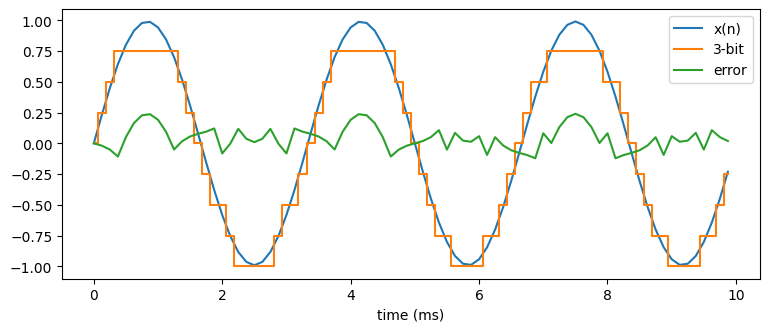

3-bit step Δ = 0.25  max |error| = 0.24


In [7]:
def quantize(x, bits, full_scale=1.0):
    delta = 2*full_scale / 2**bits
    q = np.round(x/delta)*delta
    return np.clip(q, -full_scale, full_scale - delta)

fs = 8000
t = np.arange(0, 0.01, 1/fs)
x = 0.99*np.sin(2*np.pi*300*t)
xq = quantize(x, 3)
plt.plot(t*1e3, x, label="x(n)")
plt.step(t*1e3, xq, where="mid", label="3-bit")
plt.plot(t*1e3, x - xq, label="error")
plt.xlabel("time (ms)"); plt.legend(); plt.show()
print("3-bit step Δ =", 2/2**3, " max |error| =", np.max(np.abs(x - xq)))

**Observation (2.3):** the 3-bit staircase has step Δ = 2/8 = 0.25. The error stays within ±Δ/2 = ±0.125 except near the top, where the clipping at full-scale − Δ = 0.75 makes it larger.

## Task 2.4 – Verify the 6 dB-per-bit rule

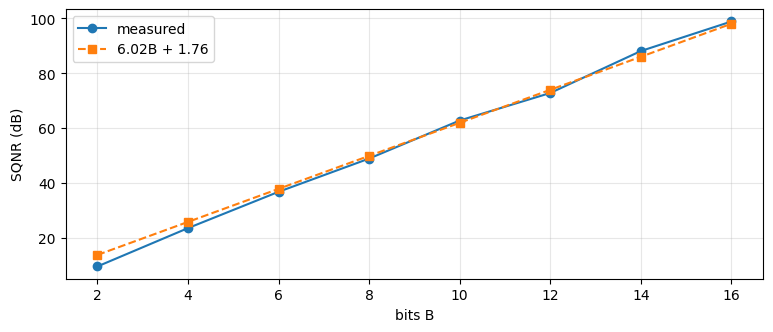

B =  2: measured   9.60 dB   theory  13.80 dB
B =  4: measured  23.58 dB   theory  25.84 dB
B =  6: measured  36.81 dB   theory  37.88 dB
B =  8: measured  48.93 dB   theory  49.92 dB
B = 10: measured  62.81 dB   theory  61.96 dB
B = 12: measured  72.84 dB   theory  74.00 dB
B = 14: measured  88.13 dB   theory  86.04 dB
B = 16: measured  98.91 dB   theory  98.08 dB
average slope per bit: 6.368190334492776


In [8]:
bits = np.arange(2, 17, 2)
meas = [10*np.log10(np.sum(x**2)/np.sum((x - quantize(x, B))**2)) for B in bits]
plt.plot(bits, meas, "o-", label="measured")
plt.plot(bits, 6.02*bits + 1.76, "s--", label="6.02B + 1.76")
plt.xlabel("bits B"); plt.ylabel("SQNR (dB)"); plt.legend(); plt.grid(alpha=0.3); plt.show()
for B, m in zip(bits, meas): print(f"B = {B:2d}: measured {m:6.2f} dB   theory {6.02*B+1.76:6.2f} dB")
print("average slope per bit:", np.polyfit(bits, meas, 1)[0])

**Observation (2.4):** the measured SQNR rises along a straight line with a fitted slope of about **6.4 dB per bit**, close to the ideal 6.02 dB/bit and close to the theory line 6.02B + 1.76. Small deviations (a few dB, either side) occur because the signal here is only 80 samples long (3 cycles), so the error is not perfectly random/uniform, and because the amplitude is 0.99 rather than exactly full-scale.

## Task 2.5 – Quantize your voice

In [9]:
fs_v, v = wavfile.read("my_voice.wav") if os.path.exists("my_voice.wav") else (fs, x)
v = v.mean(axis=1) if v.ndim > 1 else v.astype(float)
v = v / np.max(np.abs(v))
for B in [4, 8, 12]:
    vq = quantize(v, B)
    sqnr = 10*np.log10(np.sum(v**2)/np.sum((v - vq)**2))
    print(f"{B:2d} bits: SQNR = {sqnr:5.1f} dB   (full-scale sine would give {6.02*B+1.76:5.1f} dB)")
print("RMS of speech =", round(float(np.sqrt(np.mean(v**2))), 3), "  RMS of full-scale sine = 0.707")

 4 bits: SQNR =  12.3 dB   (full-scale sine would give  25.8 dB)
 8 bits: SQNR =  35.2 dB   (full-scale sine would give  49.9 dB)
12 bits: SQNR =  58.7 dB   (full-scale sine would give  74.0 dB)
RMS of speech = 0.114   RMS of full-scale sine = 0.707


In [10]:
Audio(quantize(v, 4), rate=fs_v)    # 4 bits

In [11]:
Audio(quantize(v, 8), rate=fs_v)    # 8 bits

In [12]:
Audio(quantize(v, 12), rate=fs_v)   # 12 bits

**Results:** 4 bits → 12.3 dB, 8 bits → 35.2 dB, 12 bits → 58.7 dB (each +4 bits ≈ +23 dB ≈ 6 dB/bit).
**Listening:** 4 bits has strong crackly/grainy "hiss" and the pauses are noisy/distorted; 8 bits has a faint background hiss; 12 bits is indistinguishable from the original.

**Why is speech SQNR lower than a full-scale sine?** The 6.02B + 1.76 formula assumes a full-scale sinusoid (RMS = 0.707·Xm). Speech is normalised so its *peak* is full-scale, but its RMS is only about 0.11 (peaks are rare, pauses are quiet). The quantization noise power Δ²/12 is the same, but the signal power is far smaller – about 20·log10(0.707/0.11) ≈ 16 dB lower – so the SQNR is lower by about that amount.

## Checkpoint 2
Alias table: Task 2.1. SQNR graph: Task 2.4.

## Analysis questions
**1. Why 7 Hz appears at 3 Hz when fs = 10 Hz.** On the frequency axis the spectrum of a sampled signal repeats every fs = 10 Hz. The tone at +7 Hz has an image at 7 − 10 = −3 Hz, and its mirror −7 Hz has an image at +3 Hz. Sketch: lines at ±7 Hz, replicas shifted by ±10 Hz; the replica of −7 Hz lands at +3 Hz, inside the baseband (−5, +5) Hz. The samples cos(2π·7n/10) = cos(2π·3n/10) are identical, so after sampling no one can tell the two apart.

**2. Why aliasing cannot be removed afterwards.** After sampling, the alias and a genuine low-frequency component produce *exactly the same samples* – the information about which one it was is destroyed. A filter would also remove the real signal at that frequency. The filter must therefore be applied *before* sampling/decimation (anti-aliasing filter).

**3. SQNR per extra bit.** Δ halves, so noise power falls by 4 (= 6.02 dB): +**6.02 dB per bit**. My measurement (Task 2.4 slope ≈ 6.4 dB/bit, and speech 12.3 → 35.2 → 58.7 dB for 4 → 8 → 12 bits ≈ 5.8 dB/bit) agrees.

**4. Temperature sensor.** The temperature changes by at most 0.1 °C/s, so the signal is extremely slow (bandwidth well below 1 Hz). A sampling rate of **1 Hz** (even 0.2 Hz would satisfy Nyquist; 1 Hz leaves margin and allows a simple low-pass/averaging against noise) is more than enough. Resolution: 100 °C / 0.01 °C = 10 000 levels → 2^B ≥ 10 000 → B ≥ 13.3 → **14 bits** (a 14-bit ADC gives Δ = 100/16384 ≈ 0.006 °C).

## AI-use statement
I used an AI assistant (Claude) to help generate and check the code structure of this notebook. I ran the code, checked the results against the pre-lab hand calculations, and wrote/verified the observations and answers myself.